# Midterm — Baseline model
## Predicting failed public-procurement contracts in Kazakhstan

**Author:** Aziz Abdulin · **Project:** Tender Risk ML · **Repository:** https://github.com/awzwz/tender-risk-ml

This notebook trains and evaluates the **baseline model** of the project on the modelling table prepared in
Assignment 2 (`02_data_preparation.ipynb`).

| § | Content | Midterm criterion |
|---|---|---|
| 1 | Task and data recap | — |
| 2 | Setup, data loading, sanity checks | 1 · Working code |
| 3 | Why this model? Data properties, choice, alternatives | 5 · Model selection rationale |
| 4 | Baseline configuration and training | 2 · Trained baseline model |
| 5 | Evaluation metrics and why they fit the task | 3 · At least 2 metrics |
| 6 | First experimental results and error analysis | 4 · Initial results |
| 7 | Research conclusion and next experiment | 7 · Research conclusion |

**How to run:** `Kernel → Restart & Run All` (≈ 1–2 minutes). No paths need editing: the notebook locates the
repository root itself and downloads the prepared table (23 MB) from the GitHub release if it is not present.

## 1. Task and data recap

**Task.** Binary classification: given what is known about a procurement **at the moment the winner is selected**,
predict whether the resulting contract will **fail** (be terminated or never signed). The practical use is a ranked
list for an auditor who can inspect only a small share of procurements.

**Data.** Open data of the Kazakhstan public procurement portal (OWS v3 API, goszakup.gov.kz): all procurements
published in Q1 2024 that produced at least one contract — **358,789 procurements**. Cleaning, EDA and the leakage audit
are documented in the A2 notebook.

| | |
|---|---|
| **Target** `contract_failed` | 1 if any contract of the procurement ended as *terminated* (unilaterally / by agreement) or *not concluded*; base rate **6.6 %** (imbalance ≈ 1 : 14) |
| **Features** (20) | 9 numeric (value, lots, timing, competition, organiser activity), 8 binary flags, 3 categorical (method, subject, region) — all known at award time |
| **Text** | `lot_names` — catalogue names of the purchased items (used in one experiment) |
| **Split** | chronological: train = Jan–Feb 2024, validation = 1–15 Mar, test = 16–31 Mar (74 / 15 / 11 %) |

## 2. Setup, data loading and sanity checks

In [1]:
# Google Colab only: uncomment and run this cell first.
# !git clone -q https://github.com/awzwz/tender-risk-ml
# import os; os.chdir("tender-risk-ml/notebooks")

In [2]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42                                   # every random component uses this seed

# repository root is found automatically -> no hard-coded local paths
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
C = {"Prior": "#a0aec0", "Logistic regression": "#2b6cb0", "Random forest": "#2f855a",
     "LogReg + lot text": "#b7791f", "fail": "#c53030"}

In [3]:
# The prepared table: local file -> GitHub release -> rebuild from the raw snapshot (see src/prepare.py)
df = P.load_model_table(ROOT)

X_TAB = P.FEATURES                 # 20 tabular features
X_ALL = P.FEATURES + [P.TEXT_FEATURE]
y = P.TARGET
train, val, test = (df[df.split == s] for s in ("train", "val", "test"))

print(f"table: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"numeric: {P.NUM_FEATURES}\nbinary:  {P.BIN_FEATURES}\ncategorical: {P.CAT_FEATURES}\ntext: {P.TEXT_FEATURE}")

table: 358,789 rows × 27 columns
numeric: ['log_total_sum', 'n_lots', 'bid_window_days', 'publish_to_start_days', 'n_bidders', 'bids_per_lot', 'best_bid_ratio', 'bid_price_cv', 'org_prior_buys']
binary:  ['no_bids', 'single_organizer', 'construction', 'light_industry', 'disabled_org', 'any_dumping', 'any_design_docs', 'any_consulting']
categorical: ['trade_method', 'subject_type', 'region']
text: lot_names


In [4]:
# Sanity checks: the split is chronological, disjoint, and the base rate is stable
overview = pd.DataFrame({
    s: {"rows": len(d), "share": len(d) / len(df), "failed": int(d[y].sum()), "failure rate": d[y].mean(),
        "from": d.publish_dt.min().date(), "to": d.publish_dt.max().date()}
    for s, d in (("train", train), ("val", val), ("test", test))}).T
assert train.publish_dt.max() < val.publish_dt.min() < val.publish_dt.max() < test.publish_dt.min()
assert not (set(train.id) & set(val.id)) and not (set(val.id) & set(test.id)) and not (set(train.id) & set(test.id))
assert df.id.is_unique and df[y].isin([0, 1]).all()
overview

,rows,share,failed,failure rate,from,to
train,266294,0.742,17530,0.066,2024-01-01,2024-02-29
val,53514,0.149,3683,0.069,2024-03-01,2024-03-15
test,38981,0.109,2567,0.066,2024-03-16,2024-03-31


The model will be **fitted on `train` only**. `val` is used to choose the decision threshold, and `test` is touched
once, for the final numbers — it contains procurements published *after* everything the model has seen.

## 3. Model selection rationale

The baseline was chosen from the **properties of the data** established in A2, not from popularity:

| Property of the data (A2) | What it requires from a baseline |
|---|---|
| Rare positive class (6.6 %, 1 : 14) | a model that outputs a **score/probability** so procurements can be ranked; a way to weight the rare class |
| Mixed feature types: skewed numeric, flags, categories with up to 21 levels | a model that works on standardised numbers + one-hot categories without heavy tuning |
| 266 thousand training rows, sparse one-hot / text matrices | training must scale linearly and take seconds, so experiments can be repeated |
| The result must be explained to an auditor | **interpretable** effects (sign and size per feature) |
| Missing values in competition features (16–55 %) | explicit, leakage-free imputation inside the pipeline |
| Known non-linearity (U-shape in bidders) and interactions (value × method) | the baseline should make this limitation *visible*, so a second, non-linear reference is useful |

**Chosen baseline: class-weighted logistic regression.**
1. It is the simplest model that produces a probability, so it gives the *floor* that any more complex model must beat.
2. Each coefficient is a readable statement ("request for quotations increases the log-odds of failure by …"), which
   lets us check the model against the EDA — a wrong sign would reveal a bug or leakage.
3. `class_weight="balanced"` handles the 1 : 14 imbalance inside the loss, without resampling the data.
4. It trains in about a second on 266 thousand rows and works unchanged on sparse TF-IDF text.
5. L2 regularisation keeps it stable under the collinearity found in A2 (`n_bidders` ↔ `bids_per_lot`).

**Reference models trained next to it** (to interpret the baseline, not to replace it yet):
* *Prior classifier* — predicts the base rate for everyone; shows what "no model" scores.
* *Random forest* — a standard non-linear model with default-like settings; if it beats the linear baseline, the
  gap measures how much signal sits in non-linearities and interactions.
* *Logistic regression + TF-IDF of lot names* — the same baseline plus text; tests whether *what* is bought adds
  information.

**Alternatives considered and why they are not the baseline (yet)**

| Alternative | Why not now |
|---|---|
| Gradient boosting (LightGBM / CatBoost) | expected to be the strongest tabular model, but it has many interacting hyper-parameters; tuning it is the subject of Assignment 3, and it needs a simple baseline to be compared against |
| Fine-tuned transformer on lot text | lot names are short catalogue strings (2–3 % unique); the cheap TF-IDF experiment below is the right first test before spending GPU time (planned for A3) |
| Kernel SVM | training cost grows quadratically–cubically with rows — impractical for 266 thousand; gives no probabilities natively |
| k-nearest neighbours | distances are poorly defined on mixed one-hot / numeric features; slow prediction; no interpretability |
| Naive Bayes | assumes independent features, which is violated by the strongly correlated competition block |
| Neural network (MLP) | on medium-size tabular data it rarely beats tree ensembles and needs careful tuning; no interpretability gain |
| Rule-based score (31 indicators of the earlier prototype) | hand-set thresholds, cannot be validated; will be used as a comparator in A3 |

## 4. Baseline configuration and training

**Preprocessing (inside the pipeline, fitted on `train` only — no leakage from validation/test):**
* numeric → median imputation **+ missing-value indicator** → standardisation (z-score);
* binary flags → passed through;
* categorical → one-hot encoding; levels with < 50 training rows are merged, unseen levels are ignored;
* text (only in the text experiment) → TF-IDF of word uni- and bi-grams.

In [5]:
def tabular_steps(scale: bool):
    # Column-wise preprocessing shared by all models. Trees do not need scaling.
    numeric = [SimpleImputer(strategy="median", add_indicator=True)] + ([StandardScaler()] if scale else [])
    return [("num", make_pipeline(*numeric), P.NUM_FEATURES),
            ("bin", "passthrough", P.BIN_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), P.CAT_FEATURES)]

# BASELINE ── logistic regression, L2-regularised, class-weighted
baseline = make_pipeline(
    ColumnTransformer(tabular_steps(scale=True)),
    LogisticRegression(penalty="l2", C=1.0, class_weight="balanced", solver="lbfgs", max_iter=2000, random_state=SEED),
)

# REFERENCES
prior = DummyClassifier(strategy="prior")
forest = make_pipeline(
    ColumnTransformer(tabular_steps(scale=False)),
    RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt",
                           class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
)
text_lr = make_pipeline(
    ColumnTransformer(tabular_steps(scale=True) + [
        ("txt", TfidfVectorizer(ngram_range=(1, 2), min_df=20, max_features=30_000, sublinear_tf=True), P.TEXT_FEATURE)]),
    LogisticRegression(penalty="l2", C=1.0, class_weight="balanced", solver="lbfgs", max_iter=2000, random_state=SEED),
)

MODELS = {"Prior": (prior, X_TAB), "Logistic regression": (baseline, X_TAB),
          "Random forest": (forest, X_TAB), "LogReg + lot text": (text_lr, X_ALL)}
baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: f

In [6]:
# Training: every model sees the TRAIN split only
fit_time = {}
for name, (model, cols) in MODELS.items():
    t0 = time.time()
    model.fit(train[cols], train[y])
    fit_time[name] = time.time() - t0
    print(f"{name:20s} trained on {len(train):,} rows in {fit_time[name]:5.1f} s")

Prior                trained on 266,294 rows in   0.0 s


Logistic regression  trained on 266,294 rows in   1.0 s


Random forest        trained on 266,294 rows in  10.6 s


LogReg + lot text    trained on 266,294 rows in   7.2 s


In [7]:
# Configuration and training parameters of the baseline
lr = baseline[-1]
n_inputs = baseline[0].transform(train[X_TAB].head(1)).shape[1]
config = pd.Series({
    "model": "LogisticRegression (scikit-learn)",
    "loss / penalty": "log-loss with L2 penalty",
    "C (inverse regularisation strength)": lr.C,
    "class_weight": "balanced → weight {:.2f} for 'not failed', {:.2f} for 'failed'".format(*(len(train) / (2 * np.bincount(train[y])))),
    "solver / max_iter": f"{lr.solver} / {lr.max_iter}",
    "iterations until convergence": int(lr.n_iter_[0]),
    "random_state": SEED,
    "training rows": f"{len(train):,}",
    "raw features → model inputs": f"{len(X_TAB)} → {n_inputs} (after one-hot and missing-indicators)",
    "training time, s": round(fit_time["Logistic regression"], 1),
})
config.to_frame("baseline configuration")

,baseline configuration
model,LogisticRegression (scikit-learn)
loss / penalty,log-loss with L2 penalty
C (inverse regularisation strength),1.000
class_weight,"balanced → weight 0.54 for 'not failed', 7.60 for 'failed'"
solver / max_iter,lbfgs / 2000
iterations until convergence,75
random_state,42
training rows,"266,294"
raw features → model inputs,20 → 52 (after one-hot and missing-indicators)
"training time, s",1.000


The optimiser **converged** (far fewer iterations than `max_iter`). With `class_weight="balanced"` one failed
contract weighs about as much as 14 successful ones in the loss, so the model is not allowed to ignore the rare class.

## 5. Evaluation metrics

**Why not accuracy.** With 6.6 % positives, a "model" that always answers *not failed* is 93.4 % accurate and finds
nothing. Accuracy is reported below only to demonstrate this.

| Metric | What it shows | Why it fits this task |
|---|---|---|
| **ROC-AUC** | probability that a randomly chosen *failed* procurement gets a higher score than a randomly chosen *successful* one. 0.5 = random, 1 = perfect. | measures **ranking quality** over all thresholds and does not depend on the class ratio → comparable between periods and models |
| **PR-AUC** (average precision) | average precision over all recall levels; its "random" level equals the base rate (0.066). | focuses on the **rare positive class**; unlike ROC-AUC it is not inflated by the huge number of easy negatives — the most honest single number under imbalance |
| **F1** (with precision and recall) | harmonic mean of precision (share of flagged procurements that really failed) and recall (share of failures that were flagged) at one decision threshold. | an auditor eventually needs a yes/no flag; F1 penalises both missed failures and false alarms |
| **Precision@k %, Recall@k %** | precision and recall among the k % of procurements with the highest scores. | matches the real constraint — **limited inspection capacity**: "if we can check 5 %, how many failures do we catch?" |

The **decision threshold** for F1 / precision / recall is chosen on the **validation** split (maximum F1) and then
applied unchanged to the test split, so the test numbers are not tuned.

In [8]:
def best_f1_threshold(y_true, score):
    # threshold with the highest F1 (computed on validation only)
    prec, rec, thr = precision_recall_curve(y_true, score)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return thr[np.argmax(f1[:-1])]

def at_top(y_true, score, share):
    # precision and recall among the `share` highest-scored rows
    if np.ptp(score) == 0:                         # constant score = random ranking
        return y_true.mean(), share
    top = np.argsort(-score)[: int(len(score) * share)]
    return y_true.iloc[top].mean(), y_true.iloc[top].sum() / y_true.sum()

scores, thresholds, rows = {}, {}, []
for name, (model, cols) in MODELS.items():
    p_val = model.predict_proba(val[cols])[:, 1]
    thresholds[name] = 1.0 if name == "Prior" else best_f1_threshold(val[y], p_val)   # prior flags nobody
    for split_name, part in (("validation", val), ("test", test)):
        p = model.predict_proba(part[cols])[:, 1]
        scores[name, split_name] = p
        pred = p >= thresholds[name]
        p1, r1 = at_top(part[y], p, 0.01); p5, r5 = at_top(part[y], p, 0.05)
        rows.append({"model": name, "split": split_name,
                     "ROC-AUC": roc_auc_score(part[y], p), "PR-AUC": average_precision_score(part[y], p),
                     "F1": f1_score(part[y], pred), "precision": precision_score(part[y], pred, zero_division=0),
                     "recall": recall_score(part[y], pred), "P@1%": p1, "P@5%": p5, "R@5%": r5,
                     "accuracy": accuracy_score(part[y], pred)})
results = pd.DataFrame(rows)
print("decision thresholds chosen on validation:", {k: round(float(v), 3) for k, v in thresholds.items() if k != "Prior"})

decision thresholds chosen on validation: {'Logistic regression': 0.715, 'Random forest': 0.637, 'LogReg + lot text': 0.758}


## 6. First experimental results
### 6.1 Metrics table

In [9]:
table = results.set_index(["split", "model"]).loc[["validation", "test"]]
table.to_csv(ROOT / "reports" / "midterm_metrics.csv")
table.style.format("{:.3f}").background_gradient(subset=["ROC-AUC", "PR-AUC", "F1", "P@1%", "P@5%"], cmap="Blues")

**Reading the table (test split = 16–31 March, never used for fitting or tuning).**

* **The baseline works.** Logistic regression reaches **ROC-AUC ≈ 0.79** and **PR-AUC ≈ 0.26** — four times the
  random level of 0.066. At its threshold it flags ≈ 11 % of procurements and catches **42 % of all failures**
  (recall) with 26 % precision (F1 ≈ 0.32). Among the top 1 % by score, every second procurement really failed.
* **Accuracy is misleading**, as predicted: the prior classifier has the *highest* accuracy (0.934) while detecting
  nothing; the useful models have lower accuracy because they dare to flag.
* **Validation ≈ test** for every model (ROC-AUC differs by < 0.01), so the result is not an artefact of one period.
  PR-AUC is a little lower on test, partly because the base rate itself is lower there (6.6 % vs 6.9 %).
* **Non-linearity matters:** the random forest beats the linear baseline on every metric (PR-AUC ≈ 0.30 vs 0.26,
  F1 ≈ 0.37 vs 0.32) with the same features — a direct measure of what the linear model cannot express.
* **Text helps a little:** adding TF-IDF of lot names lifts the same logistic regression to PR-AUC ≈ 0.28. The gain is
  real but modest, as expected for short catalogue-style names.

### 6.2 Ranking quality: ROC and precision–recall curves

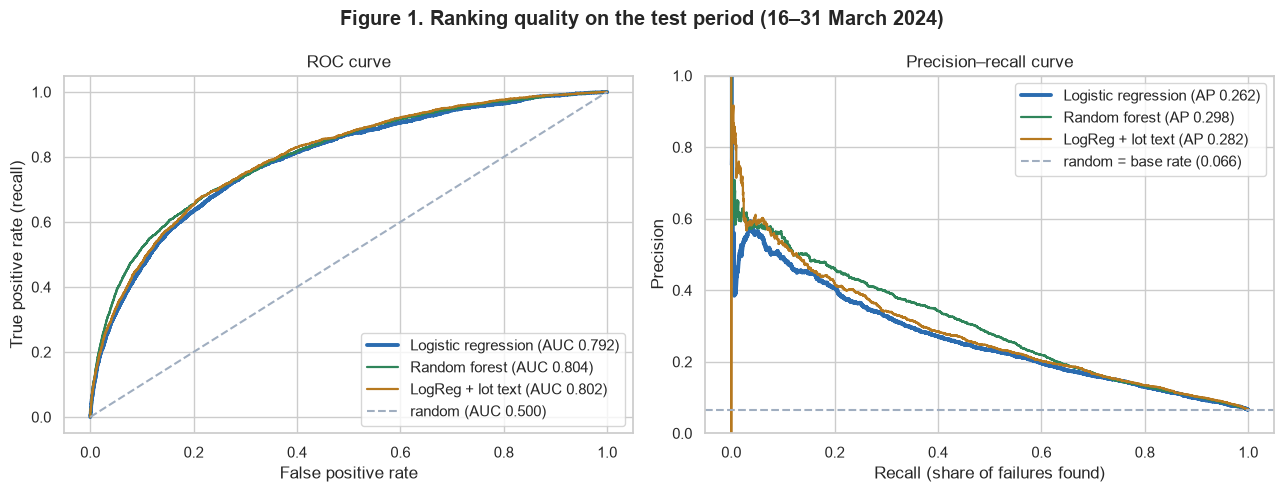

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in MODELS:
    p = scores[name, "test"]
    if name == "Prior":
        continue
    fpr, tpr, _ = roc_curve(test[y], p); prec, rec, _ = precision_recall_curve(test[y], p)
    lw = 2.8 if name == "Logistic regression" else 1.6
    axes[0].plot(fpr, tpr, color=C[name], lw=lw, label=f"{name} (AUC {roc_auc_score(test[y], p):.3f})")
    axes[1].plot(rec, prec, color=C[name], lw=lw, label=f"{name} (AP {average_precision_score(test[y], p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color=C["Prior"], label="random (AUC 0.500)")
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].axhline(test[y].mean(), ls="--", color=C["Prior"], label=f"random = base rate ({test[y].mean():.3f})")
axes[1].set(title="Precision–recall curve", xlabel="Recall (share of failures found)", ylabel="Precision", ylim=(0, 1))
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right")
fig.suptitle("Figure 1. Ranking quality on the test period (16–31 March 2024)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "mid01_roc_pr.png", dpi=150); plt.show()

**Interpretation (Figure 1).** All curves are far from the random line, and their order is the same in both plots:
random forest > logistic regression + text > logistic regression. The precision–recall plot shows the price of
imbalance: precision is high only for the first few percent of recall and drops to ≈ 0.2 by the time half of the
failures are found. The models are good at pointing to the *most* suspicious procurements, not at finding them all.

### 6.3 The auditor's view: how many failures are caught for a given inspection budget?

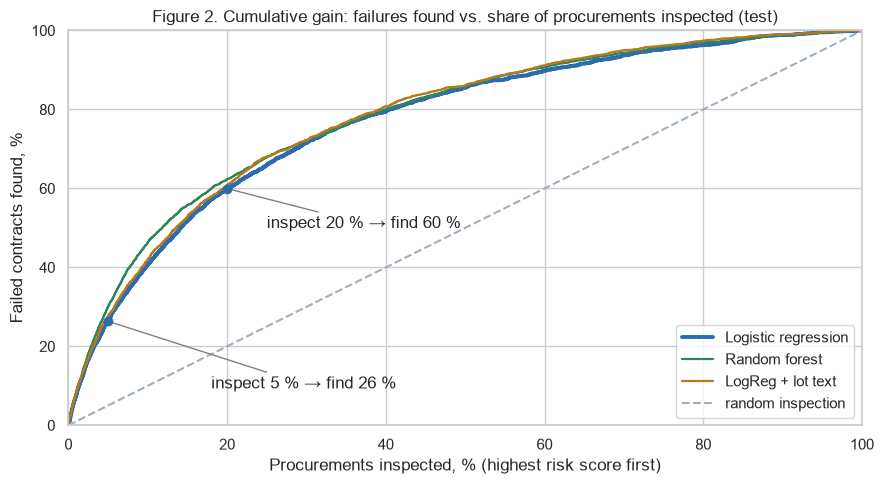

,Logistic regression,Random forest
top 1 %,precision 0.50 / recall 0.08,precision 0.56 / recall 0.09
top 5 %,precision 0.35 / recall 0.26,precision 0.40 / recall 0.30
top 10 %,precision 0.27 / recall 0.41,precision 0.31 / recall 0.46
top 20 %,precision 0.20 / recall 0.60,precision 0.21 / recall 0.62


In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
share = np.arange(1, len(test) + 1) / len(test)
for name in ("Logistic regression", "Random forest", "LogReg + lot text"):
    order = np.argsort(-scores[name, "test"])
    gain = np.cumsum(test[y].values[order]) / test[y].sum()
    ax.plot(share * 100, gain * 100, color=C[name], lw=2.8 if name == "Logistic regression" else 1.6, label=name)
ax.plot([0, 100], [0, 100], ls="--", color=C["Prior"], label="random inspection")
order = np.argsort(-scores["Logistic regression", "test"]); gain = np.cumsum(test[y].values[order]) / test[y].sum()
for k, (dx, dy) in {5: (13, -17), 20: (5, -10)}.items():
    g = gain[int(len(test) * k / 100) - 1] * 100
    ax.scatter([k], [g], color=C["Logistic regression"], zorder=5)
    ax.annotate(f"inspect {k} % → find {g:.0f} %", (k, g), xytext=(k + dx, g + dy), arrowprops=dict(arrowstyle="-", color="grey"))
ax.set(title="Figure 2. Cumulative gain: failures found vs. share of procurements inspected (test)",
       xlabel="Procurements inspected, % (highest risk score first)", ylabel="Failed contracts found, %", xlim=(0, 100), ylim=(0, 100))
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "mid02_gain.png", dpi=150); plt.show()

budget = pd.DataFrame({name: {f"top {int(k * 100)} %": "precision {:.2f} / recall {:.2f}".format(*at_top(test[y], scores[name, 'test'], k))
                              for k in (0.01, 0.05, 0.10, 0.20)} for name in ("Logistic regression", "Random forest")})
budget

**Interpretation (Figure 2).** This is the practically relevant result. Inspecting the **5 %** of procurements with the
highest baseline score finds **26 %** of all failed contracts (5× more than random inspection); inspecting **20 %**
finds **60 %**. For a control body that today selects procurements essentially at random, this is already a usable
prioritisation tool, even though the model is far from perfect.

### 6.4 Errors at the decision threshold

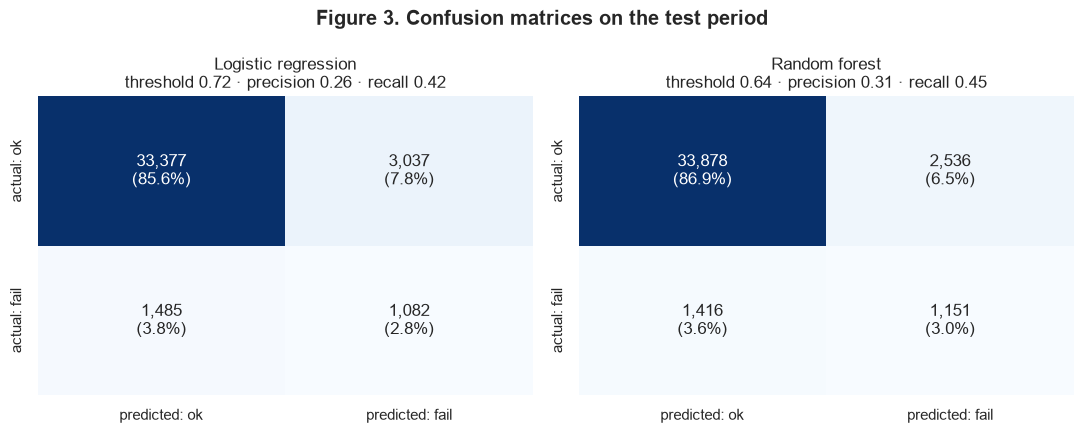

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, name in zip(axes, ("Logistic regression", "Random forest")):
    pred = scores[name, "test"] >= thresholds[name]
    cm = confusion_matrix(test[y], pred)
    sns.heatmap(cm, annot=np.array([[f"{v:,}\n({v / cm.sum():.1%})" for v in r] for r in cm]), fmt="", cmap="Blues",
                cbar=False, ax=ax, xticklabels=["predicted: ok", "predicted: fail"], yticklabels=["actual: ok", "actual: fail"])
    ax.set_title(f"{name}\nthreshold {thresholds[name]:.2f} · precision {precision_score(test[y], pred):.2f} · recall {recall_score(test[y], pred):.2f}")
fig.suptitle("Figure 3. Confusion matrices on the test period", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "mid03_confusion.png", dpi=150); plt.show()

**Interpretation (Figure 3).** At its threshold the baseline correctly flags ≈ 1,080 failed contracts, **misses ≈ 1,490**
(false negatives) and raises ≈ 3,040 false alarms — roughly three false alarms per true hit. The random forest
is better on both sides (more hits, fewer false alarms). Whether this trade-off is acceptable depends on the cost of
an inspection versus the cost of a failed contract; the threshold is a policy choice, which is why threshold-free
metrics (ROC-AUC, PR-AUC) are reported first.

### 6.5 Where does the baseline fail? Error analysis by segment

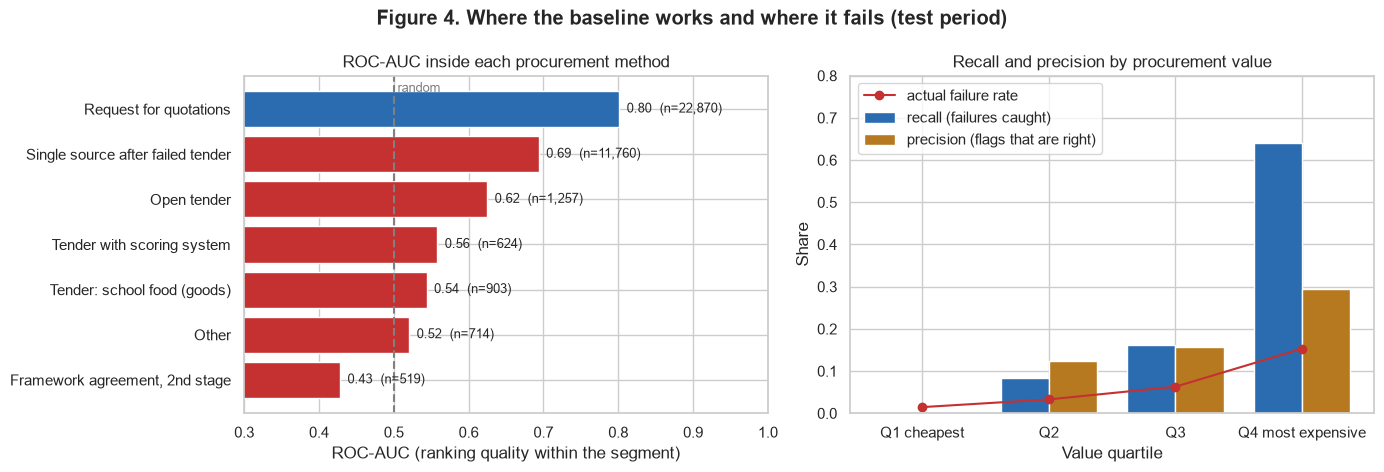

n  failure rate  ROC-AUC  recall  precision  flagged
by method  Request for quotations            22,870.000         0.091    0.801   0.484      0.315    0.140
           Single source after failed tender 11,760.000         0.020    0.694   0.084      0.073    0.023
           Open tender                        1,257.000         0.068    0.625   0.372      0.096    0.266
           Tender: school food (goods)          903.000         0.055    0.544   0.100      0.065    0.085
           Other                                714.000         0.056    0.521   0.175      0.043    0.225
           Tender with scoring system           624.000         0.059    0.558   0.135      0.122    0.066
           Framework agreement, 2nd stage       519.000         0.015    0.428   0.000      0.000    0.004
by value   Q1 cheapest                        9,746.000         0.015    0.694   0.000      0.000    0.002
           Q2                                 9,745.000         0.033    0.656   0.084      0.123    0.022
           Q3                                 9,745.000         0.063    0.675   0.163      0.156    0.066
           Q4 most expensive                  9,745.000         0.153    0.749   0.641      0.294    0.333
by subject Goods                             22,321.000         0.075    0.823   0.498      0.299    0.125
           Services                          12,329.000         0.044    0.709   0.234      0.174    0.060
           Works                              4,331.000         0.081    0.739   0.350      0.204    0.138

In [13]:
t = test.assign(score=scores["Logistic regression", "test"])
t["flag"] = t.score >= thresholds["Logistic regression"]
t["value_quartile"] = pd.qcut(t.log_total_sum, 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])

def segment(g):
    return pd.Series({"n": len(g), "failure rate": g[y].mean(),
                      "ROC-AUC": roc_auc_score(g[y], g.score) if g[y].nunique() > 1 else np.nan,
                      "recall": g.loc[g[y] == 1, "flag"].mean(),
                      "precision": g.loc[g.flag, y].mean() if g.flag.any() else np.nan,
                      "flagged": g.flag.mean()})

by_method = t.groupby("trade_method").apply(segment).query("n >= 500").sort_values("n", ascending=False)
by_value = t.groupby("value_quartile", observed=True).apply(segment)
by_subject = t.groupby("subject_type").apply(segment)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
m = by_method.sort_values("ROC-AUC")
ax.barh(m.index, m["ROC-AUC"], color=[C["Logistic regression"] if v >= 0.7 else C["fail"] for v in m["ROC-AUC"]])
ax.axvline(0.5, ls="--", color="grey"); ax.text(0.505, len(m) - 0.62, "random", color="grey", fontsize=9)
for i, (v, n) in enumerate(zip(m["ROC-AUC"], m.n)): ax.text(v + 0.01, i, f"{v:.2f}  (n={n:,.0f})", va="center", fontsize=9)
ax.set(title="ROC-AUC inside each procurement method", xlabel="ROC-AUC (ranking quality within the segment)", ylabel="", xlim=(0.3, 1.0))
ax = axes[1]
w = 0.38; x = np.arange(len(by_value))
ax.bar(x - w / 2, by_value.recall, w, label="recall (failures caught)", color=C["Logistic regression"])
ax.bar(x + w / 2, by_value.precision.fillna(0), w, label="precision (flags that are right)", color=C["LogReg + lot text"])
ax.plot(x, by_value["failure rate"], marker="o", color=C["fail"], label="actual failure rate")
ax.set_xticks(x); ax.set_xticklabels(by_value.index)
ax.set(title="Recall and precision by procurement value", xlabel="Value quartile", ylabel="Share", ylim=(0, 0.8)); ax.legend()
fig.suptitle("Figure 4. Where the baseline works and where it fails (test period)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "mid04_segments.png", dpi=150); plt.show()
pd.concat({"by method": by_method, "by value": by_value, "by subject": by_subject})

In [14]:
# Who are the missed failures (FN) and the false alarms (FP)?
fn = t[(t[y] == 1) & ~t.flag]; tp = t[(t[y] == 1) & t.flag]; fp = t[(t[y] == 0) & t.flag]; tn = t[(t[y] == 0) & ~t.flag]
profile = pd.DataFrame({
    "true positives (caught)": {"n": len(tp), "median value, KZT": 10 ** tp.log_total_sum.median(),
                                "share request for quotations": (tp.trade_method == "Request for quotations").mean(),
                                "share goods": (tp.subject_type == "Goods").mean(), "partially executed": np.nan},
    "false negatives (missed)": {"n": len(fn), "median value, KZT": 10 ** fn.log_total_sum.median(),
                                 "share request for quotations": (fn.trade_method == "Request for quotations").mean(),
                                 "share goods": (fn.subject_type == "Goods").mean(), "partially executed": np.nan},
    "false positives (false alarms)": {"n": len(fp), "median value, KZT": 10 ** fp.log_total_sum.median(),
                                       "share request for quotations": (fp.trade_method == "Request for quotations").mean(),
                                       "share goods": (fp.subject_type == "Goods").mean(), "partially executed": fp.partially_executed.mean()},
    "true negatives": {"n": len(tn), "median value, KZT": 10 ** tn.log_total_sum.median(),
                       "share request for quotations": (tn.trade_method == "Request for quotations").mean(),
                       "share goods": (tn.subject_type == "Goods").mean(), "partially executed": tn.partially_executed.mean()},
}).T
profile.style.format({"n": "{:,.0f}", "median value, KZT": "{:,.0f}", "share request for quotations": "{:.1%}",
                      "share goods": "{:.1%}", "partially executed": "{:.1%}"}, na_rep="—")

,n,"median value, KZT",share request for quotations,share goods,partially executed
true positives (caught),"1,082","3,260,660",93.6%,76.9%,—
false negatives (missed),"1,485","468,000",72.6%,56.6%,—
false positives (false alarms),"3,037","3,000,000",72.4%,64.2%,4.8%
true negatives,"33,377","160,714",55.7%,56.0%,3.0%


**Where the model errs (Figure 4 and the tables).**

1. **It is mostly a detector of large requests for quotations.** Inside that method ranking is good (ROC-AUC ≈ 0.80),
   but inside the others it is weak: ≈ 0.69 for single-source purchases, ≈ 0.63 for open tenders and close to random
   for the small tender types. The model has learned *between-method* differences well and *within-method* differences
   poorly — except for the largest group.
2. **Cheap procurements are invisible.** In the cheapest value quartile the baseline flags almost nothing, so its recall
   there is ≈ 0, and it stays below 20 % in Q2–Q3; almost 90 % of the failures it catches are in the most expensive
   quartile. A linear model can only say "more expensive = riskier"; it cannot find the risky cheap purchases.
3. **Missed failures (false negatives)** are typically mid-value procurements (median ≈ 0.5 million KZT against
   ≈ 3.3 million for the caught ones) — failures without the obvious "large contract" signal.
4. **False alarms are not all wrong.** Flagged-but-not-failed procurements are large and look like the true hits, and they
   ended *partially executed* more often than the unflagged ones (≈ 4.8 % vs 3.0 %) — some "errors" are near misses
   that the binary label counts as success.

### 6.6 Are the scores real probabilities? Calibration

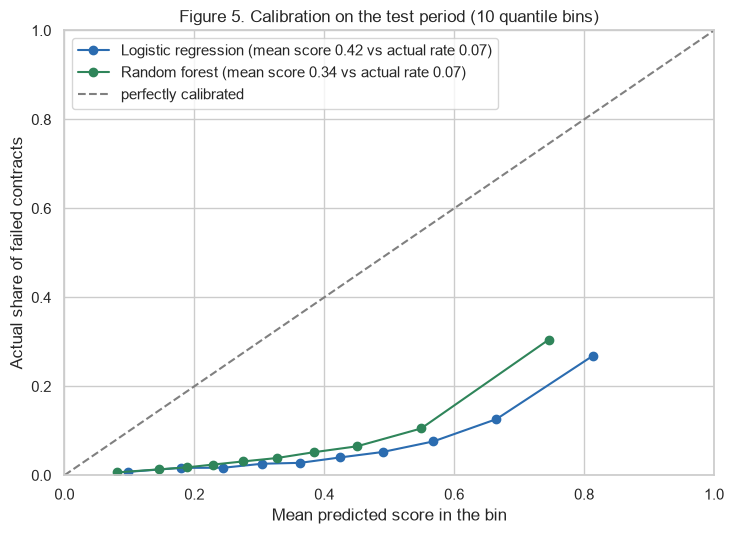

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name in ("Logistic regression", "Random forest"):
    frac, mean_pred = calibration_curve(test[y], scores[name, "test"], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", color=C[name],
            label=f"{name} (mean score {scores[name, 'test'].mean():.2f} vs actual rate {test[y].mean():.2f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="perfectly calibrated")
ax.set(title="Figure 5. Calibration on the test period (10 quantile bins)", xlabel="Mean predicted score in the bin",
       ylabel="Actual share of failed contracts", xlim=(0, 1), ylim=(0, 1)); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "mid05_calibration.png", dpi=150); plt.show()

**Interpretation (Figure 5).** The scores **rank** procurements correctly (curves rise monotonically) but they are
**not probabilities**: class weighting makes the model behave as if failures were as frequent as successes, so even a
baseline score of ≈ 0.8 corresponds to a real failure rate below 0.3, and the average score (0.42) is six times the
actual failure rate (0.07). This does not affect ROC-AUC, PR-AUC or the top-k lists, but
the raw score must not be shown to a user as "70 % risk". Probability calibration (isotonic / Platt on validation) is a
required step before the model is used for anything but ranking.

### 6.7 What drives the predictions?

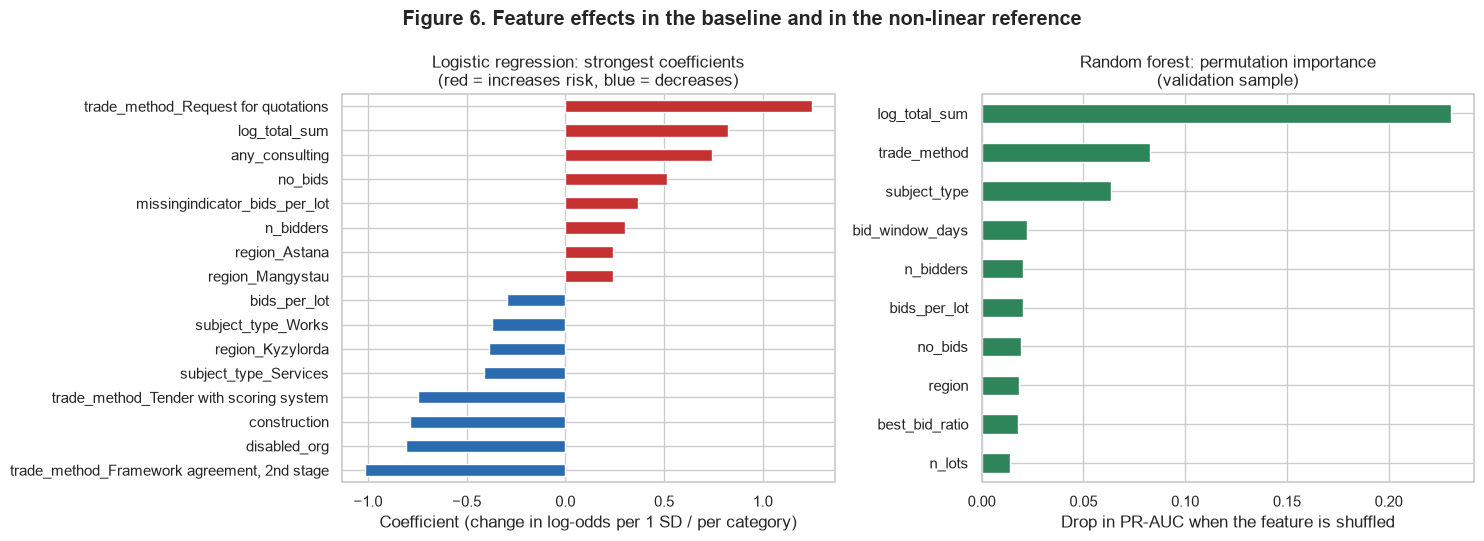

In [16]:
coef = pd.Series(baseline[-1].coef_[0], index=[n.split("__", 1)[1] for n in baseline[0].get_feature_names_out()])
top = pd.concat([coef.nlargest(8), coef.nsmallest(8)]).sort_values()

# permutation importance of the random forest on a validation sample (drop in PR-AUC when one feature is shuffled)
sample = val.sample(15_000, random_state=SEED)
perm = permutation_importance(forest, sample[X_TAB], sample[y], scoring="average_precision", n_repeats=3, random_state=SEED)
imp = pd.Series(perm.importances_mean, index=X_TAB).sort_values().tail(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top.plot.barh(ax=axes[0], color=[C["fail"] if v > 0 else C["Logistic regression"] for v in top])
axes[0].set(title="Logistic regression: strongest coefficients\n(red = increases risk, blue = decreases)",
            xlabel="Coefficient (change in log-odds per 1 SD / per category)", ylabel="")
imp.plot.barh(ax=axes[1], color=C["Random forest"])
axes[1].set(title="Random forest: permutation importance\n(validation sample)", xlabel="Drop in PR-AUC when the feature is shuffled", ylabel="")
fig.suptitle("Figure 6. Feature effects in the baseline and in the non-linear reference", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "mid06_features.png", dpi=150); plt.show()

**Interpretation (Figure 6).** The baseline's coefficients have the signs expected from the EDA — a useful sanity check
that the model learned real structure and not an artefact: *request for quotations*, a higher **procurement value**
and the **absence of recorded offers** raise the risk; **framework agreements**, scoring-system tenders and
**services** (relative to goods) lower it. The opposite signs of `n_bidders` (+) and `bids_per_lot` (−) are a symptom
of their collinearity and of the U-shaped effect that one linear term cannot represent. In the random forest,
**procurement value** is by far the most important feature, followed by the procurement method and the subject of
purchase, and then by the timing and competition features — the same factors, but used non-linearly.

### 6.8 Robustness check: a stricter definition of failure

In [17]:
strict = pd.DataFrame({name: {"ROC-AUC (main label)": roc_auc_score(test[y], scores[name, "test"]),
                              "ROC-AUC (strict label)": roc_auc_score(test.contract_failed_strict, scores[name, "test"]),
                              "PR-AUC (strict label)": average_precision_score(test.contract_failed_strict, scores[name, "test"])}
                       for name in ("Logistic regression", "Random forest", "LogReg + lot text")}).T
print(f"strict label = unilateral termination / not concluded only; base rate {test.contract_failed_strict.mean():.3f}")
strict

strict label = unilateral termination / not concluded only; base rate 0.053


,ROC-AUC (main label),ROC-AUC (strict label),PR-AUC (strict label)
Logistic regression,0.792,0.826,0.255
Random forest,0.804,0.836,0.293
LogReg + lot text,0.802,0.828,0.266


The models were trained on the main label, yet they separate the **strict** failures (unilateral termination or not
concluded — without terminations "by mutual agreement") even better: ROC-AUC rises to ≈ 0.83. The signal is therefore
not produced by the noisier "agreement" terminations; it is strongest for the unambiguous failures.

In [18]:
# persist the trained baseline (models/ is git-ignored)
import joblib
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump({"model": baseline, "threshold": float(thresholds["Logistic regression"]), "features": X_TAB},
            ROOT / "models" / "baseline_logreg.joblib")
print("saved models/baseline_logreg.joblib and reports/midterm_metrics.csv")

saved models/baseline_logreg.joblib and reports/midterm_metrics.csv


## 7. Research conclusion

**What the first experiment showed.** Information available at the moment of award carries real predictive signal
about contract failure. A deliberately simple, interpretable baseline — class-weighted logistic regression on 20
features — ranks unseen March procurements with **ROC-AUC 0.79 and PR-AUC 0.26 (4× the base rate)**; the top 5 % of its
list contains a quarter of all failures. The result is stable between validation and test and holds for a stricter
definition of failure, so it is not an artefact of the period or of label noise.

**Is the result acceptable?** As a *prioritisation* tool — yes: it is several times better than random selection.
As a *detector* — not yet: at the operating threshold it misses more than half of the failures and gives about three
false alarms per hit.

**Limitations revealed.**
1. *Linearity.* The baseline mainly separates large requests for quotations from everything else; it has almost no
   power inside other methods and among cheap purchases. The random forest's gain (+0.04 PR-AUC, +0.04 F1 with the
   same features) shows the missing non-linearities and interactions are worth modelling.
2. *Uncalibrated scores* — usable for ranking only.
3. *Features.* No track record of suppliers/organisers (cannot be built without leakage), text used only as bag-of-words.
4. *Data.* One quarter; the label mixes supplier failures with customer decisions; a binary label hides "partially
   executed" near misses.

**Next experiment (Assignment 3).** Train **gradient boosting** (LightGBM / CatBoost) on the same split with systematic
hyper-parameter optimisation, and compare it with this baseline and the random forest; add **probability calibration**;
extend the text branch from TF-IDF to a **fine-tuned multilingual transformer** on lot names and combine it with the
tabular model; report per-segment metrics to verify that the improvement comes from the segments where the baseline
fails (non-quotation methods, low-value purchases).